In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib 
import shap
import os

C:\Users\Zhores\Desktop\MLOps\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
np.random.seed(42)

In [3]:
model = joblib.load('artifacts/xgb_model.pkl')

In [4]:
X_test = pd.read_pickle('artifacts/X_test.pkl')
y_test = pd.read_pickle('artifacts/y_test.pkl')

In [5]:
fraud_indices = y_test[y_test == 1].index
legit_indices = y_test[y_test == 0].index

In [6]:
sample_fraud_idx = np.random.choice(fraud_indices, size=min(50, len(fraud_indices)), replace=False)
sample_legit_idx = np.random.choice(legit_indices, size=950, replace=False)
sample_idx = np.concatenate([sample_fraud_idx, sample_legit_idx])

In [7]:
X_sample = X_test.loc[sample_idx].copy()
y_sample = y_test.loc[sample_idx].copy()

In [8]:
explainer = shap.TreeExplainer(model)

In [9]:
shap_values = explainer(X_sample)

C:\Users\Zhores\AppData\Local\Temp\ipykernel_13160\2712430325.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_sample, show=False)


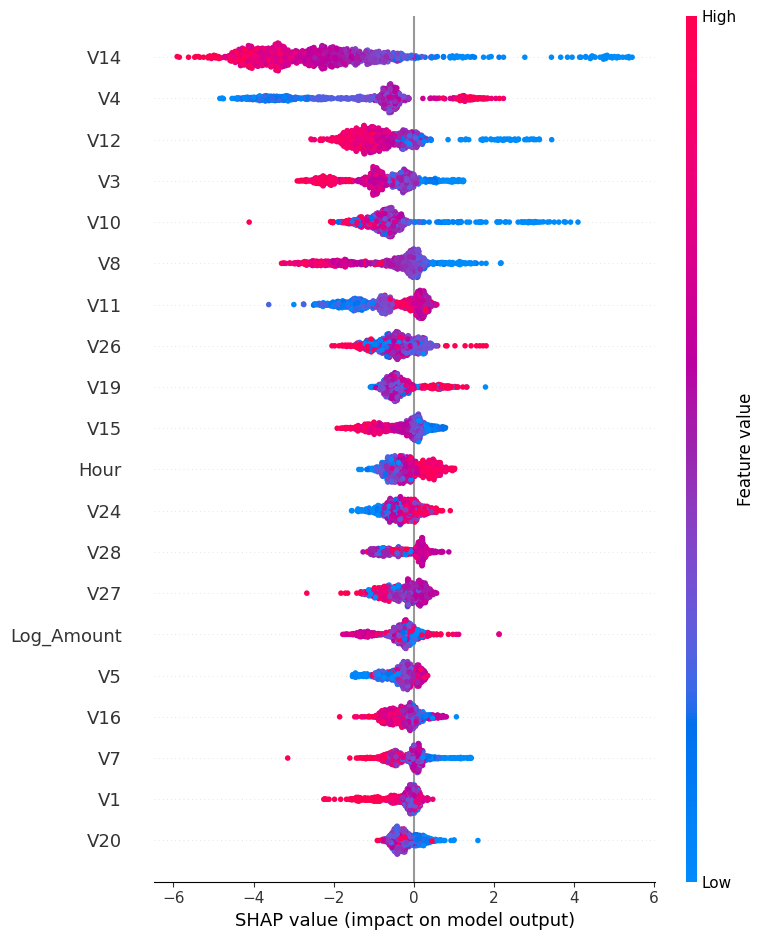

In [10]:
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample, show=False)
plt.tight_layout()
plt.savefig('plots/shap_global_importance.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
y_sample_proba = model.predict_proba(X_sample)[:, 1]
fraud_mask = (y_sample == 1) & (y_sample_proba > 0.8)
legit_mask = (y_sample == 0) & (y_sample_proba < 0.2)

In [12]:
if fraud_mask.any():
    idx_fraud = fraud_mask.idxmax()
else:
    idx_fraud = y_sample[y_sample == 1].index[0]
if legit_mask.any():
    idx_legit = legit_mask.idxmax()
else:
    idx_legit = y_sample[y_sample == 0].index[0]

pos_fraud = X_sample.index.get_loc(idx_fraud)
pos_legit = X_sample.index.get_loc(idx_legit)

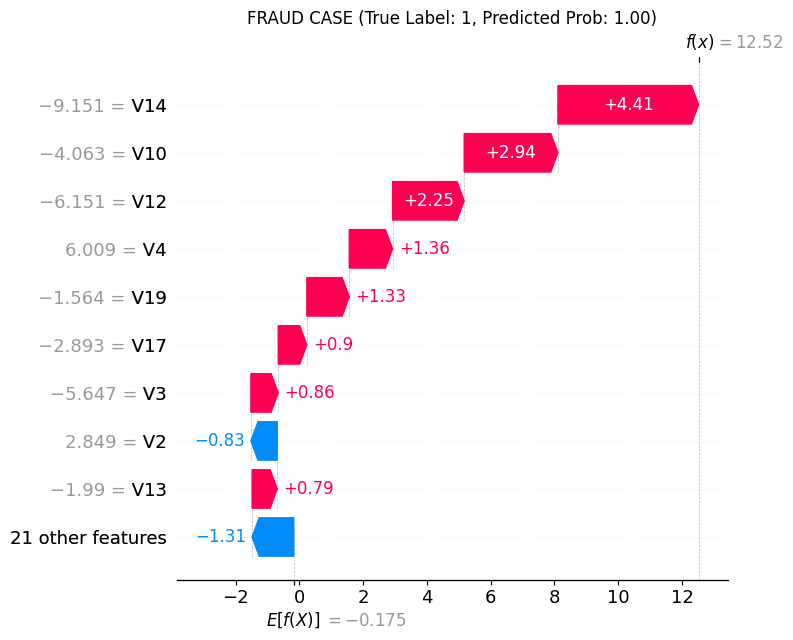

In [13]:
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[pos_fraud], show=False)
plt.title(f"FRAUD CASE (True Label: 1, Predicted Prob: {y_sample_proba[pos_fraud]:.2f})")
plt.tight_layout()
plt.savefig('plots/shap_waterfall_fraud.png', dpi=300, bbox_inches='tight')
plt.show()

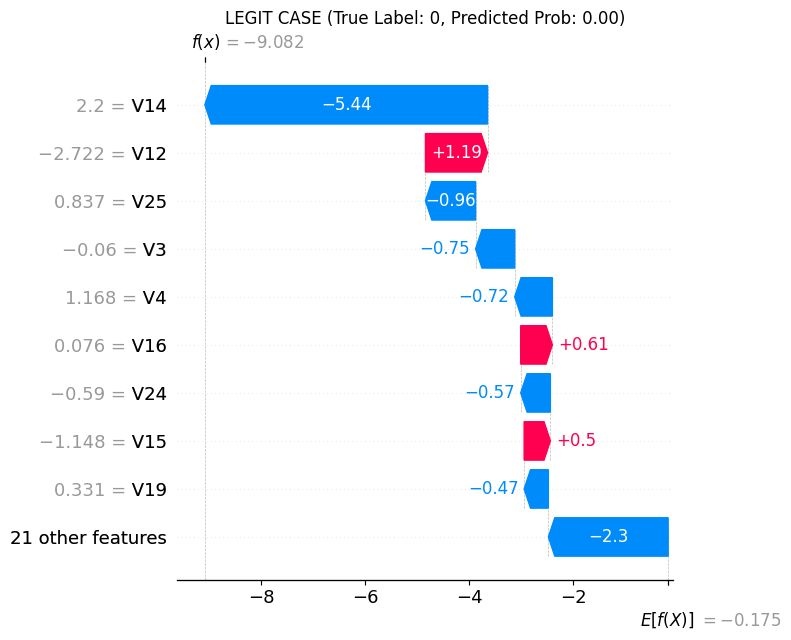

In [14]:
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[pos_legit], show=False)
plt.title(f"LEGIT CASE (True Label: 0, Predicted Prob: {y_sample_proba[pos_legit]:.2f})")
plt.tight_layout()
plt.savefig('plots/shap_waterfall_legit.png', dpi=300, bbox_inches='tight')
plt.show()